# Markov Chain Model Continued

To further build on work from group sprint one, more code using the markov chain formula, First change we can make is looking at creating a non-homogeneous model, so the probabilites between each state are different at different times.

More to look at:
- Chain with the bill data/ pay back data
- seperating the state of fully paid/ not required -2,-1 from 0 (min payed)
- combining models in parallel to reduce weaknesses
- cross validation/ changing the threshold for denial

Then Analyse models: 
- Confusion Matrix
- AUC/ PR curve
- brier scoring
- 

In [9]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix

In [10]:
# load the cleaned Taiwan data made by 01-Introduction
ROOT = Path.cwd().parent
taiwan = pd.read_csv(ROOT / "data" / "processed" / "taiwan-clean.csv", index_col="ID")

In [11]:
#order data chronologically by month (PAY_1 is the most recent month, PAY_6 is the oldest)
months = ["Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct"]
pay_cols  = ["PAY_6", "PAY_5", "PAY_4", "PAY_3", "PAY_2", "PAY_1"]
bill_cols = [f"BILL_AMT{i}" for i in range(6, 0, -1)]
amt_cols  = [f"PAY_AMT{i}" for i in range(6, 0, -1)]

# create table which shows the relevant data from the cleaned dataframe for a given client (row)
def client_table(taiwan, n=0):
    r = taiwan.iloc[n]
    return pd.DataFrame(
        [list(range(1, 8)),
         list(r[pay_cols]) + [r["default payment next month"]],
         list(r[bill_cols]) + [r["default payment next month"]],
         list(r[amt_cols]) + [r["default payment next month"]]],
        index=["Month no.", "Status (PAY / default label)", "BILL_AMT", "PAY_AMT"],
        columns=months,
    )

print(client_table(taiwan, 1))

                               Apr   May   Jun   Jul   Aug   Sep  Oct
Month no.                        1     2     3     4     5     6    7
Status (PAY / default label)     2     0     0     0     2    -1    1
BILL_AMT                      3261  3455  3272  2682  1725  2682    1
PAY_AMT                       2000     0  1000  1000  1000     0    1


In [20]:
def to_state(p):
    p = np.asarray(p)
    s = np.empty(p.shape, dtype=int)
    s[p <= -1] = 0          # no consumption/paid in full
    s[p == 0] = 1          # revolving credit
    s[p == 1]  = 2          # 1 month late
    s[p == 2]  = 3          # 2 months late
    s[p >= 3]  = 4          # 3+ months late
    return s

In [18]:
#two alternative versions of the to_state function, one split between no consumption and paid in full, the other combining them into one state
def to_state(p):
    p = np.asarray(p)
    s = np.empty(p.shape, dtype=int)
    s[p == -2] = 0          # no consumption
    s[p == -1] = 1          # paid in full
    s[p == 0]  = 2          # revolving credit
    s[p == 1]  = 3          # 1 month late
    s[p >= 2]  = 4          # 2+ months late
    return s

target column: default payment next month
AUC      : 0.735
Accuracy : 0.736  (threshold=-1.53)
[[5403 1605]
 [ 772 1219]]

P(non-default):
           none   full  revolv  1m late  2m+ late
none      0.856  0.091   0.033    0.020     0.000
full      0.053  0.909   0.000    0.038     0.000
revolv    0.038  0.038   0.846    0.038     0.038
1m late   0.119  0.244   0.127    0.461     0.048
2m+ late  0.074  0.066   0.102    0.255     0.503

P(default):
           none   full  revolv  1m late  2m+ late
none      0.811  0.082   0.054    0.053     0.000
full      0.040  0.796   0.000    0.164     0.000
revolv    0.083  0.083   0.667    0.083     0.083
1m late   0.046  0.111   0.081    0.686     0.075
2m+ late  0.044  0.047   0.068    0.301     0.540


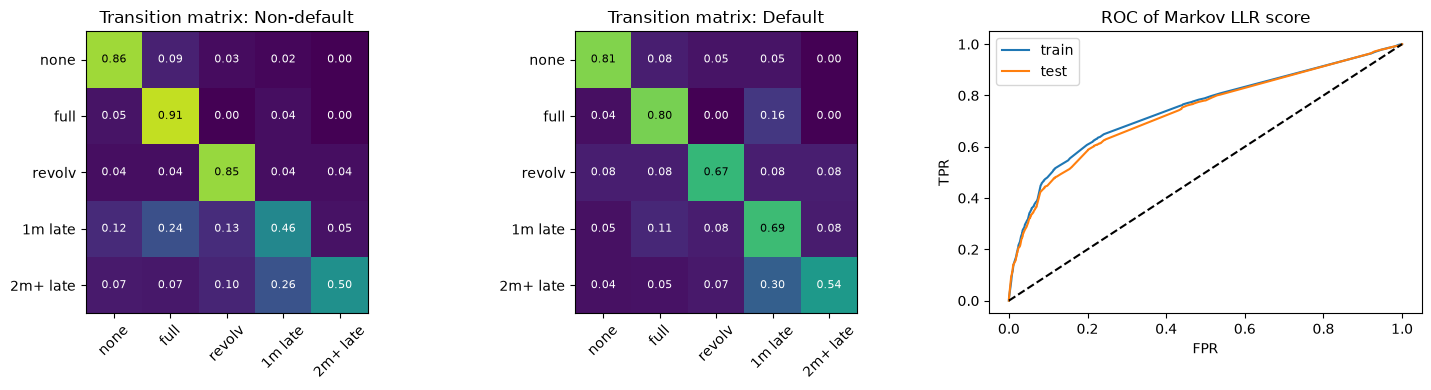

AUC of 'P(late next month | Sep state)': 0.605


In [ ]:
# --- Markov chain default model (continues from your notebook) ---
TARGET = [c for c in taiwan.columns if "default" in c.lower()][0]   # or set explicitly
print("target column:", TARGET)

K = 5
S = to_state(taiwan[pay_cols].values)          # chronological: Apr..Sep
y = taiwan[TARGET].values.astype(int)

S_tr, S_te, y_tr, y_te = train_test_split(
    S, y, test_size=0.3, stratify=y, random_state=42)

def fit_chain(S, alpha=1.0):
    init = np.bincount(S[:, 0], minlength=K) + alpha
    init = init / init.sum()
    counts = np.zeros((K, K)) + alpha                 # Laplace smoothing
    for a, b in zip(S[:, :-1].ravel(), S[:, 1:].ravel()):
        counts[a, b] += 1
    P = counts / counts.sum(axis=1, keepdims=True)
    return init, P

init0, P0 = fit_chain(S_tr[y_tr == 0])
init1, P1 = fit_chain(S_tr[y_tr == 1])
log_prior = np.log(y_tr.mean() / (1 - y_tr.mean()))

def llr(S, use_prior=True):
    score = np.log(init1[S[:, 0]]) - np.log(init0[S[:, 0]])
    for t in range(S.shape[1] - 1):
        score += np.log(P1[S[:, t], S[:, t+1]]) - np.log(P0[S[:, t], S[:, t+1]])
    return score + (log_prior if use_prior else 0)

# choose threshold on TRAIN data (Youden's J) so the minority class isn't ignored
from sklearn.metrics import roc_curve
s_tr = llr(S_tr)
fpr, tpr, thr = roc_curve(y_tr, s_tr)
best_thr = thr[np.argmax(tpr - fpr)]

s_te = llr(S_te)
pred = (s_te > best_thr).astype(int)
print(f"AUC      : {roc_auc_score(y_te, s_te):.3f}")
print(f"Accuracy : {accuracy_score(y_te, pred):.3f}  (threshold={best_thr:.2f})")
print(confusion_matrix(y_te, pred))

# --- inspect the learned chains ---
names = ["none", "full", "revolv", "1m late", "2m+ late"]
for lab, P in [("non-default", P0), ("default", P1)]:
    print(f"\nP({lab}):")
    print(pd.DataFrame(P, index=names, columns=names).round(3))

# --- plot the two transition matrices side by side ---
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, P, t in zip(ax[:2], [P0, P1], ["Non-default", "Default"]):
    im = a.imshow(P, vmin=0, vmax=1, cmap="viridis")
    a.set_xticks(range(K)); a.set_xticklabels(names, rotation=45)
    a.set_yticks(range(K)); a.set_yticklabels(names)
    a.set_title(f"Transition matrix: {t}")
    for i in range(K):
        for j in range(K):
            a.text(j, i, f"{P[i,j]:.2f}", ha="center", va="center",
                   color="w" if P[i, j] < 0.6 else "k", fontsize=8)
ax[2].plot(fpr, tpr, label="train")
f2, t2, _ = roc_curve(y_te, s_te)
ax[2].plot(f2, t2, label="test"); ax[2].plot([0, 1], [0, 1], "k--")
ax[2].set_xlabel("FPR"); ax[2].set_ylabel("TPR"); ax[2].legend()
ax[2].set_title("ROC of Markov LLR score")
plt.tight_layout(); plt.show()

# --- one-step-ahead prediction: what does the pooled chain say about October? ---
init_all, P_all = fit_chain(S_tr)
p_late_next = P_all[S_te[:, -1], 3:].sum(axis=1)     # P(next state is >= 1 month late)
print("AUC of 'P(late next month | Sep state)':",
      round(roc_auc_score(y_te, p_late_next), 3))

                          Brier  BSS vs baseline  reliability  resolution  \
model                                                                       
Baseline (base rate)     0.1723           0.0000       0.0000        0.00   
Markov raw               0.1431           0.1694       0.0014        0.03   
Markov Platt-calibrated  0.1427           0.1720       0.0012        0.03   

                         uncertainty     AUC  
model                                         
Baseline (base rate)          0.1723  0.5000  
Markov raw                    0.1723  0.7346  
Markov Platt-calibrated       0.1723  0.7346  


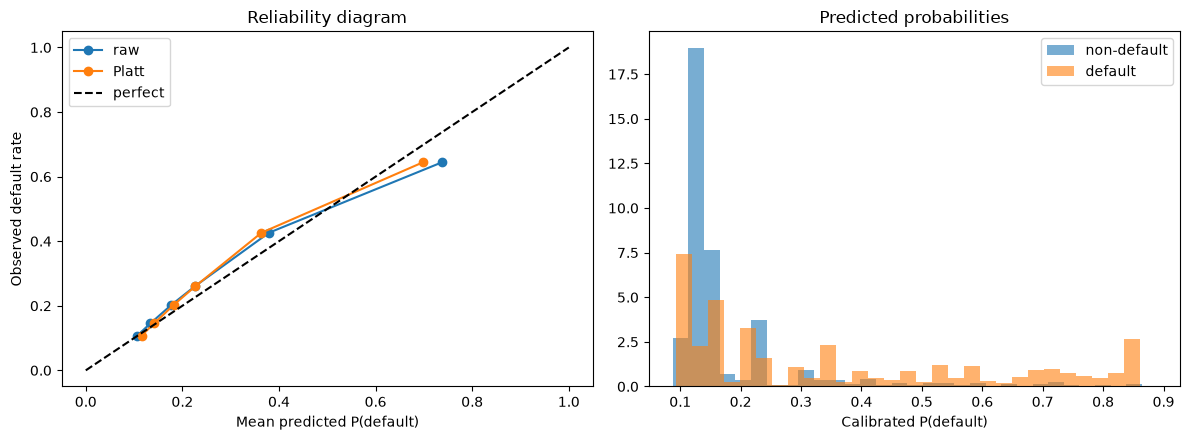

In [22]:
from sklearn.metrics import brier_score_loss
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# raw probabilities from the Markov likelihood-ratio model
p_tr_raw = sigmoid(llr(S_tr))
p_te_raw = sigmoid(llr(S_te))

# Platt recalibration: p = sigmoid(a*score + b), fitted on training scores
platt = LogisticRegression(C=1e6).fit(llr(S_tr).reshape(-1, 1), y_tr)
p_te_cal = platt.predict_proba(llr(S_te).reshape(-1, 1))[:, 1]

# baseline: always predict the training default rate
p_base = np.full(len(y_te), y_tr.mean())

def brier_decomp(p, y, bins=10):
    """Murphy decomposition: BS = reliability - resolution + uncertainty"""
    edges = np.linspace(0, 1, bins + 1)
    idx = np.clip(np.digitize(p, edges) - 1, 0, bins - 1)
    ybar = y.mean(); n = len(y)
    rel = res = 0.0
    for k in range(bins):
        m = idx == k
        if m.any():
            nk, pk, ok = m.sum(), p[m].mean(), y[m].mean()
            rel += nk * (pk - ok) ** 2
            res += nk * (ok - ybar) ** 2
    return rel / n, res / n, ybar * (1 - ybar)

rows = []
for name, p in [("Baseline (base rate)", p_base),
                ("Markov raw", p_te_raw),
                ("Markov Platt-calibrated", p_te_cal)]:
    bs = brier_score_loss(y_te, p)
    rel, res, unc = brier_decomp(p, y_te)
    rows.append({"model": name, "Brier": bs,
                 "BSS vs baseline": 1 - bs / brier_score_loss(y_te, p_base),
                 "reliability": rel, "resolution": res, "uncertainty": unc,
                 "AUC": roc_auc_score(y_te, p)})
brier_table = pd.DataFrame(rows).set_index("model").round(4)
print(brier_table)

# reliability diagram
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for name, p in [("raw", p_te_raw), ("Platt", p_te_cal)]:
    frac_pos, mean_pred = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    ax[0].plot(mean_pred, frac_pos, "o-", label=name)
ax[0].plot([0, 1], [0, 1], "k--", label="perfect")
ax[0].set_xlabel("Mean predicted P(default)")
ax[0].set_ylabel("Observed default rate")
ax[0].set_title("Reliability diagram"); ax[0].legend()

ax[1].hist(p_te_cal[y_te == 0], bins=30, alpha=.6, label="non-default", density=True)
ax[1].hist(p_te_cal[y_te == 1], bins=30, alpha=.6, label="default", density=True)
ax[1].set_xlabel("Calibrated P(default)"); ax[1].set_title("Predicted probabilities")
ax[1].legend(); plt.tight_layout(); plt.show()

Graphs show strong conistency in certainty predicting non defaulters from this model, but weak varying certainty when trying to predict the defaulters. non-homogeneous chain, chain of other features combine. and analyse.